# ЛР №5. Запуск открытой модели text-to-image

**Выполнил:** Котов Дэвид Арсенович  
**Группа:**  
**Проверил:**

**Вариант 27:** 27 = (5 − 1) · 6 + 3 — бриф 5 «обложка электронного музыкального релиза» × условие 3 «генератор CPU и GPU».

| Параметр | Значение |
| --- | --- |
| Бриф | металл с радужными бликами, макросъёмка, сильный контраст |
| Условие | устройство генератора: A — CPU, B — CUDA |
| Seed | 1027 в обоих условиях |
| Модель | stabilityai/sd-turbo |
| Ревизия | b261bac6fd2cf515557d5d0707481eafa0485ec2 |
| Фиксировано | запрос, GPU модели, float16, 512×512, один шаг, guidance_scale=0.0 |
| Допуск | identical — равны пиксели; close — PSNR ≥40 дБ; different — PSNR <40 дБ |

Модель работает на GPU в обоих случаях. Меняется только устройство генератора начального шума. Библиотека преподавателя используется без изменений.


## Данные и лицензия

Вход — бриф 5 из `BRIEFS`:

> cover art for an electronic music release, brushed metal surface with iridescent reflections, macro photography style, strong contrast, no text, no logo, no people

Это учебный концепт обложки: без реальных людей, чужих знаков и имитации стиля конкретного живущего художника.

На закреплённой ревизии находится [Stability AI Community License Agreement](https://huggingface.co/stabilityai/sd-turbo/blob/b261bac6fd2cf515557d5d0707481eafa0485ec2/LICENSE.md) от 5 июля 2024 г.; использование учебное и некоммерческое. Условия лицензии модели и её производных отличаются от условий для выходных изображений. При распространении модели и производных применяются требования раздела IV(a) об уведомлении, копии лицензии и атрибуции. Действует [политика допустимого использования](https://stability.ai/use-policy).

Powered by Stability AI.

Ограничения модели: читаемый текст не гарантируется; PSNR пары не измеряет красоту или соответствие брифу. Соответствие металлической поверхности и радужных бликов оценивается отдельно по обоим изображениям.


## Шаг 1. Подготовка среды

Основная среда — Google Colab с GPU T4. Для условия CPU/CUDA нужна CUDA; запуск всей модели на CPU не заменяет этот эксперимент.

Фиксируются diffusers 0.40.0 и transformers 5.16.1 — версии методических указаний. Предустановленный torch не заменяется. Фактические версии, GPU и CUDA сохраняются в манифестах.


In [1]:
import os, sys, time, shutil, pathlib, platform, importlib, subprocess
from importlib.metadata import version as pkg_version, PackageNotFoundError

T_START = time.perf_counter()
WORK = pathlib.Path.cwd()
if WORK.name != "LR05":
    WORK = WORK / "LR05"
WORK.mkdir(parents=True, exist_ok=True)
os.chdir(WORK)
if str(WORK) not in sys.path:
    sys.path.insert(0, str(WORK))
print("Рабочая папка: LR05")

import torch
if not torch.cuda.is_available():
    raise SystemExit("Для варианта 27 нужна CUDA. Выберите GPU T4 и запустите ноутбук заново.")

PINS = {"diffusers": "0.40.0", "transformers": "5.16.1"}
def installed_version(pkg):
    try:
        return pkg_version(pkg)
    except PackageNotFoundError:
        return None

todo = [f"{k}=={v}" for k, v in PINS.items() if installed_version(k) != v]
todo += [p for p in ("accelerate", "safetensors", "Pillow") if installed_version(p) is None]
if todo:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *todo], check=True)
    importlib.invalidate_caches()
    if any(m in sys.modules for m in PINS):
        raise SystemExit("Пакеты обновлены. Перезапустите сеанс и выполните ноутбук с начала.")
print("Установлены версии:", {p: installed_version(p) for p in PINS})


Рабочая папка: LR05
Установлены версии: {'diffusers': '0.40.0', 'transformers': '5.16.1'}


Следующая ячейка записывает фактическое окружение. Версии из методических указаний не выдаются за версии текущего сеанса.


In [2]:
import numpy as np
import torch, diffusers, transformers, PIL

CUDA = torch.cuda.is_available()
DEVICE_NAME = torch.cuda.get_device_name(0)
driver = subprocess.run(["nvidia-smi", "--query-gpu=driver_version", "--format=csv,noheader"],
                        capture_output=True, text=True)
ENV = dict(python=sys.version.split()[0], platform=platform.platform(), device=DEVICE_NAME,
           cuda=torch.version.cuda, cudnn=torch.backends.cudnn.version(),
           driver=driver.stdout.strip() if driver.returncode == 0 else None,
           gpu_memory_gib=round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 1),
           packages={p: pkg_version(p) for p in ("torch", "diffusers", "transformers", "Pillow", "numpy", "accelerate", "safetensors")})
for key, value in ENV.items():
    print(key, "=", value)


python = 3.13.16
platform = Linux-6.6.159+-x86_64-with-glibc2.39
device = Tesla T4
cuda = 13.0
cudnn = 92700
driver = 580.82.07
gpu_memory_gib = 14.6
packages = {'torch': '2.11.0+cu130', 'diffusers': '0.40.0', 'transformers': '5.16.1', 'Pillow': '11.3.0', 'numpy': '2.1.3', 'accelerate': '1.15.0', 'safetensors': '0.8.0'}


## Шаг 1 (продолжение). Учебная библиотека

Ячейка `%%writefile` сохраняет выданный `lab05_lib.py`. Библиотека не изменяется; далее проверяются размер и полный SHA-256.


In [3]:
%%writefile lab05_lib.py
# ЛР 5. Запуск открытой модели text-to-image. Библиотека учебных функций.
# Проверено 19.09.2026: Google Colab, GPU T4, Python 3.13, torch 2.11.0+cu128, diffusers 0.40.0, transformers 5.16.1.
# Модель: stabilityai/sd-turbo, ревизия закреплена (см. REVISION). Веса загружаются с Hugging Face без авторизации.
import hashlib, io, time
import numpy as np
import torch
from PIL import Image
from diffusers import AutoPipelineForText2Image
from diffusers.utils import logging as dlog

dlog.set_verbosity_error()  # убирает предупреждения о приведении типов при pipe.to(dtype)

MODEL_ID = "stabilityai/sd-turbo"
REVISION = "b261bac6fd2cf515557d5d0707481eafa0485ec2"

# Пять контекстов (брифов). Во всех запретены текст, логотипы и люди.
BRIEFS = [
    "editorial poster concept for a robotics festival, glowing mechanical arm silhouette, deep blue and amber palette, clean composition, no text, no logo, no people",
    "square podcast cover about the city environment, abstract layered skyline of geometric shapes, teal and orange palette, minimal flat style, no text, no people",
    "poster concept for a science exhibition, abstract constellation of connected nodes, dark background with white and cyan lines, balanced composition, no text, no logo",
    "visual for an ecology lecture series, stylized forest canopy seen from above, layered green shapes, soft morning light, no text, no people",
    "cover art for an electronic music release, brushed metal surface with iridescent reflections, macro photography style, strong contrast, no text, no logo, no people",
]


def load_pipe(dtype=torch.float16):
    """Загружает закреплённую ревизию (файлы fp16) на GPU; dtype задаёт тип вычислений."""
    pipe = AutoPipelineForText2Image.from_pretrained(
        MODEL_ID, revision=REVISION, torch_dtype=torch.float16, variant="fp16", use_safetensors=True)
    pipe.set_progress_bar_config(disable=True)
    return pipe.to("cuda", dtype)


def generate(pipe, prompt, seed, steps=1, guidance=0.0, size=512, batch=1, gen_device="cpu"):
    """Возвращает список PIL-изображений. Для каждого элемента пакета свой генератор: seed, seed+1, ..."""
    gens = [torch.Generator(device=gen_device).manual_seed(seed + i) for i in range(batch)]
    return pipe(prompt=[prompt] * batch, num_inference_steps=steps, guidance_scale=guidance,
                height=size, width=size, generator=gens).images


def generate_fixed_noise(pipe, prompt, seed, steps=1, guidance=0.0, size=512):
    """Начальный шум всегда строится в float32 и приводится к типу вычислений: так меняется только точность."""
    g = torch.Generator(device="cpu").manual_seed(seed)
    lat = torch.randn((1, 4, size // 8, size // 8), generator=g, dtype=torch.float32).to("cuda", pipe.unet.dtype)
    return pipe(prompt=[prompt], num_inference_steps=steps, guidance_scale=guidance, height=size, width=size, latents=lat).images[0]


def png_bytes(img):
    buf = io.BytesIO()
    img.save(buf, format="PNG")
    return buf.getvalue()


def sha(data):
    return hashlib.sha256(data).hexdigest()


def to_arr(img):
    return np.asarray(img.convert("RGB"), dtype=np.float64)


def psnr_db(a, b):
    """PSNR для значений 0..255; inf, если изображения совпадают."""
    mse = np.mean((to_arr(a) - to_arr(b)) ** 2)
    return float("inf") if mse == 0 else 10 * np.log10(255.0 ** 2 / mse)


def max_abs_diff(a, b):
    return int(np.max(np.abs(to_arr(a) - to_arr(b))))


def jpeg_roundtrip(img, quality=90):
    buf = io.BytesIO()
    img.save(buf, format="JPEG", quality=quality)
    buf.seek(0)
    return Image.open(buf).convert("RGB"), buf.getvalue()


def classify(psnr, tol_db=40.0):
    """Классификация пары по допуску, заданному до эксперимента."""
    return "identical" if psnr == float("inf") else ("close" if psnr >= tol_db else "different")


# Шесть условий сравнения (фактор варианта). Каждое условие даёт пару изображений A и B.
CONDITIONS = ["repeat", "seed_plus_1", "generator_device", "dtype", "file_format", "batch"]


def make_pair(pipe, prompt, seed, cond):
    if cond == "repeat":
        a = generate(pipe, prompt, seed)[0]; b = generate(pipe, prompt, seed)[0]
    elif cond == "seed_plus_1":
        a = generate(pipe, prompt, seed)[0]; b = generate(pipe, prompt, seed + 1)[0]
    elif cond == "generator_device":
        a = generate(pipe, prompt, seed, gen_device="cpu")[0]; b = generate(pipe, prompt, seed, gen_device="cuda")[0]
    elif cond == "dtype":
        pipe.to(torch.float16); a = generate(pipe, prompt, seed)[0]
        pipe.to(torch.float32); b = generate(pipe, prompt, seed)[0]
        pipe.to(torch.float16)
    elif cond == "file_format":
        a = generate(pipe, prompt, seed)[0]; b, _ = jpeg_roundtrip(a, 90)
    elif cond == "batch":
        a = generate(pipe, prompt, seed)[0]; b = generate(pipe, prompt, seed, batch=4)[0]
    else:
        raise ValueError(cond)
    return a, b


def variant_summary(pipe, n):
    """Вариант n = 1..30: контекст c = (n-1)//6 + 1, условие k = (n-1)%6 + 1."""
    c, k = (n - 1) // 6, (n - 1) % 6
    seed = 1000 + n
    t0 = time.perf_counter()
    a, b = make_pair(pipe, BRIEFS[c], seed, CONDITIONS[k])
    dt = time.perf_counter() - t0
    p = psnr_db(a, b)
    pf = None
    if CONDITIONS[k] == "dtype":  # проверка причины: одинаковый начальный шум в обоих режимах
        pipe.to(torch.float16); fa = generate_fixed_noise(pipe, BRIEFS[c], seed)
        pipe.to(torch.float32); fb = generate_fixed_noise(pipe, BRIEFS[c], seed)
        pipe.to(torch.float16); pf = psnr_db(fa, fb)
    return dict(variant=n, ctx=c + 1, cond=CONDITIONS[k], seed=seed, sha_a=sha(png_bytes(a)), sha_b=sha(png_bytes(b)),
                pixel_equal=bool(np.array_equal(to_arr(a), to_arr(b))), max_diff=max_abs_diff(a, b), psnr=p,
                verdict=classify(p), seconds=round(dt, 2), psnr_fixed_noise=pf)


Writing lab05_lib.py


Проверка целостности библиотеки: 6447 байт, SHA-256 `4eb176506585ffcda1702605a767309fb451808229c3622f80ce882b7fa2ce1a`.


In [4]:
import hashlib

LIB_PATH = WORK / "lab05_lib.py"
lib_bytes = LIB_PATH.read_bytes()
if not lib_bytes.endswith(b"\n") and hashlib.sha256(lib_bytes + b"\n").hexdigest().startswith("4eb17650"):
    lib_bytes += b"\n"
    LIB_PATH.write_bytes(lib_bytes)
    print("Восстановлен завершающий перевод строки, отброшенный редактором ячейки")
LIB_SHA = hashlib.sha256(lib_bytes).hexdigest()
print("Размер, байт:", len(lib_bytes))
print("SHA-256     :", LIB_SHA)
LIB_OK = len(lib_bytes) == 6447 and LIB_SHA.startswith("4eb17650")
print("Совпадает с указаниями (6447 байт, 4eb17650…):", LIB_OK)
assert LIB_OK, "библиотека введена с ошибкой — сверить текст ячейки с приложением А"

Размер, байт: 6447
SHA-256     : 4eb176506585ffcda1702605a767309fb451808229c3622f80ce882b7fa2ce1a
Совпадает с указаниями (6447 байт, 4eb17650…): True


In [5]:
import lab05_lib as L
print("Модель:", L.MODEL_ID)
print("Ревизия:", L.REVISION)


[transformers] `Siglip2ImageProcessorFast` is deprecated. The `Fast` suffix for image processors has been removed; use `Siglip2ImageProcessor` instead.


Модель: stabilityai/sd-turbo
Ревизия: b261bac6fd2cf515557d5d0707481eafa0485ec2


## Шаг 2. Гипотеза и допуск до запуска

Гипотеза и допуск записаны в `LR05/reports/journal.md` до генерации.

**Гипотеза:** при одном seed 1027 генераторы CPU и CUDA создадут разный начальный шум. Ожидаются разные SHA-256, несовпадающие пиксели и PSNR <40 дБ, вердикт **different**. Точное значение PSNR заранее не задано.

**Допуск:** identical — пиксели совпадают; close — пиксели различаются, но PSNR ≥40 дБ; different — PSNR <40 дБ. Порог после запуска не меняется.

Ожидается, что свежий генератор с тем же устройством и seed воспроизведёт результат в пределах текущего сеанса. Если передать один и тот же готовый шум, различие от устройства его создания должно исчезнуть; это проверяется отдельно. Вывод не переносится автоматически на другую платформу.


## Шаг 3. Загрузка модели и прогрев

Загружается закреплённая ревизия, файлы fp16, формат safetensors. Конвейер остаётся на CUDA и во float16. Прогрев не входит в основной опыт.


In [6]:
t0 = time.perf_counter()
pipe = L.load_pipe()
load_s = time.perf_counter() - t0
DTYPE = str(pipe.unet.dtype).replace("torch.", "")
print(f"Загрузка модели: {load_s:.1f} с | устройство конвейера: {pipe.device} | тип вычислений: {DTYPE}")

t0 = time.perf_counter()
L.generate(pipe, L.BRIEFS[4], 1)
print(f"Прогрев (seed 1): {time.perf_counter() - t0:.1f} с")

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_validators.py:206: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(


model_index.json:   0%|          | 0.00/616 [00:00<?, ?B/s]

/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 12 files:   0%|          | 0/12 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/5 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/372 [00:00<?, ?it/s]

Загрузка модели: 26.0 с | устройство конвейера: cuda:0 | тип вычислений: float16
Прогрев (seed 1): 4.7 с


## Шаг 4. Базовый запуск и манифест

Бриф 5, seed 1027, генератор на CPU; модель на GPU. Изображение и условия сохраняются вместе, затем выполняется повтор со свежим генератором. Новая базовая серия получает следующий номер run.


Папка запуска: LR05/artifacts/run_001
{
  "model_id": "stabilityai/sd-turbo",
  "revision": "b261bac6fd2cf515557d5d0707481eafa0485ec2",
  "prompt": "cover art for an electronic music release, brushed metal surface with iridescent reflections, macro photography style, strong contrast, no text, no logo, no people",
  "seed": 1027,
  "steps": 1,
  "guidance_scale": 0.0,
  "size": 512,
  "generator_device": "cpu",
  "dtype": "float16",
  "device": "Tesla T4",
  "platform": "Linux-6.6.159+-x86_64-with-glibc2.39",
  "python": "3.13.16",
  "packages": {
    "torch": "2.11.0+cu130",
    "diffusers": "0.40.0",
    "transformers": "5.16.1",
    "Pillow": "11.3.0",
    "numpy": "2.1.3",
    "accelerate": "1.15.0",
    "safetensors": "0.8.0"
  },
  "cuda": "13.0",
  "cudnn": 92700,
  "nvidia_driver": "580.82.07",
  "pipeline": "StableDiffusionPipeline",
  "scheduler": "EulerDiscreteScheduler",
  "load_seconds": 26.0,
  "generation_seconds": 0.33,
  "image_size": [
    512,
    512
  ],
  "image_mo

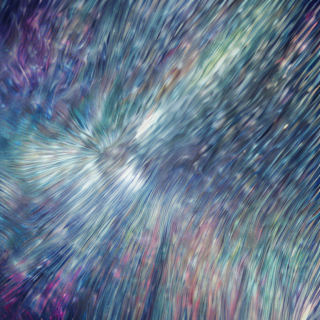

In [7]:
import json
from datetime import datetime, timezone
from IPython.display import display

N = 27
PROMPT, SEED, STEPS, GUIDANCE, SIZE = L.BRIEFS[4], 1000 + N, 1, 0.0, 512
ART = WORK / "artifacts"
k = 1
while (ART / f"run_{k:03d}" / "manifest.json").exists():
    k += 1
out = ART / f"run_{k:03d}"
out.mkdir(parents=True, exist_ok=True)

t0 = time.perf_counter()
img = L.generate(pipe, PROMPT, SEED, STEPS, GUIDANCE, SIZE)[0]
gen_s = time.perf_counter() - t0

data = L.png_bytes(img)
(out / "result.png").write_bytes(data)
manifest = dict(
    model_id=L.MODEL_ID, revision=L.REVISION, prompt=PROMPT, seed=SEED,
    steps=STEPS, guidance_scale=GUIDANCE, size=SIZE, generator_device="cpu",
    dtype=DTYPE, device=DEVICE_NAME, platform=ENV["platform"], python=ENV["python"],
    packages=ENV["packages"], cuda=ENV["cuda"], cudnn=ENV["cudnn"], nvidia_driver=ENV["driver"],
    pipeline=type(pipe).__name__, scheduler=type(pipe.scheduler).__name__,
    load_seconds=round(load_s, 1), generation_seconds=round(gen_s, 2),
    image_size=list(img.size), image_mode=img.mode, sha256=L.sha(data), lib_sha256=LIB_SHA,
    date_utc=datetime.now(timezone.utc).isoformat(), variant=N,
    weights_variant="fp16", use_safetensors=True, tolerance_psnr_db=40.0)
(out / "manifest.json").write_text(json.dumps(manifest, ensure_ascii=False, indent=2), encoding="utf-8")
print("Папка запуска:", out.relative_to(WORK.parent))
print(json.dumps(manifest, ensure_ascii=False, indent=2))

again = L.generate(pipe, PROMPT, SEED, STEPS, GUIDANCE, SIZE)[0]
REPEAT_CPU = L.sha(L.png_bytes(again)) == manifest["sha256"]
print("Повтор CPU со свежим генератором, SHA-256 совпал:", REPEAT_CPU)
display(img.resize((320, 320)))


## Шаг 5. Сравнение по условию варианта

`variant_summary(pipe, 27)` выбирает бриф 5, условие generator_device и seed 1027. A использует генератор CPU, B — CUDA; модель в обоих случаях на GPU. Для данного условия `psnr_fixed_noise` не применяется: проверка причины выполнена отдельной ячейкой.


In [8]:
S = L.variant_summary(pipe, N)
assert (S["ctx"], S["cond"], S["seed"]) == (5, "generator_device", SEED)
rows = [("вариант / бриф / условие", f'{S["variant"]} / {S["ctx"]} / {S["cond"]}'),
        ("seed A / seed B", f"{SEED} / {SEED}"), ("генератор A / B", "cpu / cuda"),
        ("SHA-256 A", S["sha_a"]), ("SHA-256 B", S["sha_b"]),
        ("совпадение пикселей", S["pixel_equal"]), ("максимум различия (0…255)", S["max_diff"]),
        ("PSNR, дБ", S["psnr"]), ("вердикт (допуск 40 дБ)", S["verdict"]),
        ("время пары, с", S["seconds"]), ("psnr_fixed_noise", S["psnr_fixed_noise"])]
w = max(len(row[0]) for row in rows)
for name, value in rows:
    print(f"{name:<{w}} | {value}")
summary = {key: (str(value) if isinstance(value, float) and not np.isfinite(value) else value) for key, value in S.items()}
summary["repeat_cpu_sha_equal"] = REPEAT_CPU
(ART / "variant_27_summary.json").write_text(json.dumps(summary, ensure_ascii=False, indent=2), encoding="utf-8")


вариант / бриф / условие  | 27 / 5 / generator_device
seed A / seed B           | 1027 / 1027
генератор A / B           | cpu / cuda
SHA-256 A                 | 30bdc1a4b905e91934e24b2ba7830a625449149dd9eaef949a33a69557bbc51f
SHA-256 B                 | 747691d2648d94414f966c46c2a9962e7ecdc2fefc1afa35e78d23163b90bf0e
совпадение пикселей       | False
максимум различия (0…255) | 231
PSNR, дБ                  | 13.044457078558441
вердикт (допуск 40 дБ)    | different
время пары, с             | 0.77
psnr_fixed_noise          | None


413

### Изображения пары A и B

Изображения сохраняются отдельно с манифестом для каждого условия. Метрики сводки сопоставляются с сохранёнными файлами; для B меняется generator_device, а seed остаётся 1027. Общая иллюстрация пары не участвует в расчёте PSNR.


A совпадает с A из variant_summary: True
B совпадает с B из variant_summary: True


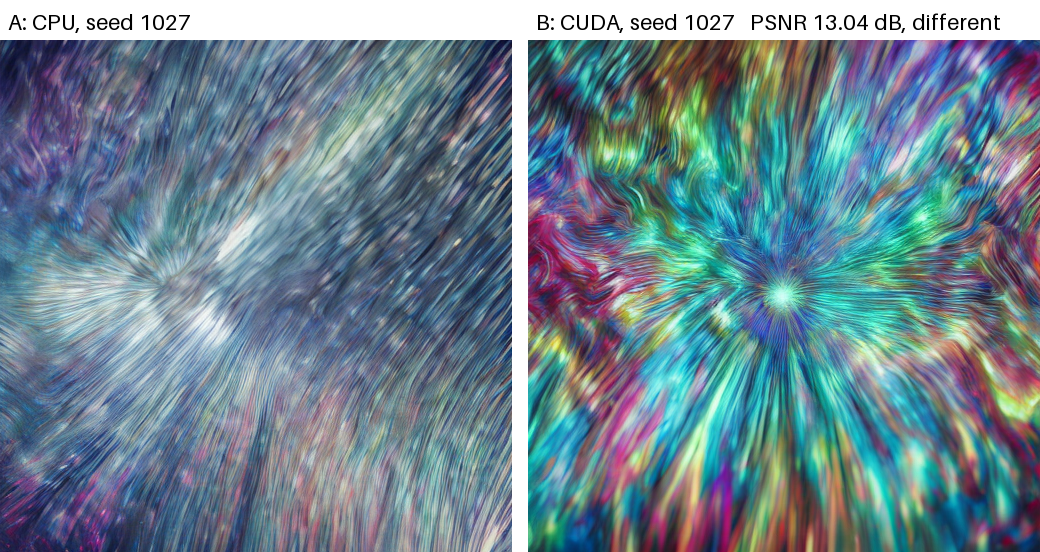

условие A: seed 1027, генератор cpu, SHA-256 30bdc1a4b905e91934e24b2ba7830a625449149dd9eaef949a33a69557bbc51f
условие B: seed 1027, генератор cuda, SHA-256 747691d2648d94414f966c46c2a9962e7ecdc2fefc1afa35e78d23163b90bf0e
Сохранённая пара совпала со сводкой: True


In [9]:
from PIL import Image, ImageDraw, ImageFont

img_a = img
img_b = L.generate(pipe, PROMPT, SEED, gen_device="cuda")[0]
sha_a, sha_b = L.sha(L.png_bytes(img_a)), L.sha(L.png_bytes(img_b))
print("A совпадает с A из variant_summary:", sha_a == S["sha_a"])
print("B совпадает с B из variant_summary:", sha_b == S["sha_b"])

pair = ART / "pair"
pair.mkdir(parents=True, exist_ok=True)
(pair / f"A_cpu_seed{SEED}.png").write_bytes(L.png_bytes(img_a))
(pair / f"B_cuda_seed{SEED}.png").write_bytes(L.png_bytes(img_b))

try:
    font = ImageFont.load_default(size=22)
except TypeError:
    font = ImageFont.load_default()
gap, head = 16, 40
comp = Image.new("RGB", (2 * SIZE + gap, SIZE + head), "white")
comp.paste(img_a, (0, head))
comp.paste(img_b, (SIZE + gap, head))
d = ImageDraw.Draw(comp)
d.text((8, 8), f"A: CPU, seed {SEED}", fill="black", font=font)
d.text((SIZE + gap + 8, 8), f"B: CUDA, seed {SEED}   PSNR {S['psnr']:.2f} dB, {S['verdict']}", fill="black", font=font)
comp.save(pair / "comparison.png")
display(comp)

# Артефакты варианта (variants_lr05.json): result.png и manifest.json для условий A и B
for tag, im, gen_device in (("A", img_a, "cpu"), ("B", img_b, "cuda")):
    cdir = ART / f"condition_{tag}"
    cdir.mkdir(parents=True, exist_ok=True)
    png = L.png_bytes(im)
    (cdir / "result.png").write_bytes(png)
    cm = dict(manifest, seed=SEED, generator_device=gen_device, sha256=L.sha(png), condition=tag, generation_seconds=None,
              date_utc=datetime.now(timezone.utc).isoformat())
    (cdir / "manifest.json").write_text(json.dumps(cm, ensure_ascii=False, indent=2), encoding="utf-8")
    print(f"условие {tag}: seed {SEED}, генератор {gen_device}, SHA-256 {cm['sha256']}")

SAVED_PAIR_OK = sha_a == S["sha_a"] and sha_b == S["sha_b"]
print("Сохранённая пара совпала со сводкой:", SAVED_PAIR_OK)
if not SAVED_PAIR_OK:
    raise RuntimeError("Повторная генерация не совпала со сводкой: сохраните вывод и разберите расхождение до оформления результата.")


### Визуальная оценка пары

**A, генератор CPU.** Преобладает холодная серебристо-синяя палитра с фиолетовыми и зелёными переливами. Тонкие диагональные штрихи сходятся к светлому участку слева от центра.

**B, генератор CUDA.** Радужные цвета ярче: бирюзовый, зелёный, пурпурный. Штрихи расходятся из яркого центра ближе к середине кадра; рисунок бликов и композиция отличаются от A.

На обоих изображениях блестящая радужная фактура занимает весь кадр и остаётся главным элементом; явных людей, текста и логотипов не видно. Материал стилизован: особенно в B он может восприниматься как волокна или абстрактное свечение, поэтому узнаваемость именно металла неоднозначна. Соответствие брифу — с этой оговоркой; низкий PSNR сам по себе не означает плохое качество обложки.


## Шаг 6. Проверка причины различия

Создаётся начальный шум с одинаковым seed 1027, но генераторами CPU и CUDA. Оба тензора имеют одну форму и dtype. Затем каждый тензор подаётся в модель через latents без генератора: проверяется, воспроизводятся ли A и B.

Контроль: один и тот же тензор CPU подаётся в два запуска с разными устройствами Generator. Это отделяет различие начального шума от возможной дополнительной случайности в конвейере. Все совпадения измеряются; если контроль не сработает, объяснение одним начальным шумом требует уточнения.


In [10]:
shape = (1, pipe.unet.config.in_channels, SIZE // 8, SIZE // 8)
noise = {device: torch.randn(shape, generator=torch.Generator(device=device).manual_seed(SEED),
                             device=device, dtype=pipe.unet.dtype) for device in ("cpu", "cuda")}
na, nb = (noise[device].float().cpu().flatten().numpy() for device in ("cpu", "cuda"))
print("Начальный шум CPU / CUDA совпадает:", np.array_equal(na, nb))
print("Максимум разности шума:", float(np.max(np.abs(na - nb))))
print("Корреляция шума:", float(np.corrcoef(na, nb)[0, 1]))

CAUSE = dict(seed=SEED, noise_equal=bool(np.array_equal(na, nb)),
             noise_max_diff=float(np.max(np.abs(na - nb))),
             noise_correlation=float(np.corrcoef(na, nb)[0, 1]))
for device, reference, tag in (("cpu", sha_a, "A"), ("cuda", sha_b, "B")):
    x = pipe(prompt=[PROMPT], num_inference_steps=STEPS, guidance_scale=GUIDANCE,
             height=SIZE, width=SIZE, latents=noise[device].to(pipe.device).clone()).images[0]
    CAUSE[f"fixed_latents_reproduce_{tag}"] = L.sha(L.png_bytes(x)) == reference
    print(f"Готовый шум {device} воспроизвёл {tag} бит в бит:", CAUSE[f"fixed_latents_reproduce_{tag}"])

control_sha = {}
for device in ("cpu", "cuda"):
    x = pipe(prompt=[PROMPT], num_inference_steps=STEPS, guidance_scale=GUIDANCE,
             height=SIZE, width=SIZE, latents=noise["cpu"].to(pipe.device).clone(),
             generator=[torch.Generator(device=device).manual_seed(SEED)]).images[0]
    control_sha[device] = L.sha(L.png_bytes(x))
CAUSE["same_latents_sha_equal"] = control_sha["cpu"] == control_sha["cuda"]
CAUSE["control_sha256"] = control_sha
print("Общий готовый шум, разные устройства Generator — SHA совпали:", CAUSE["same_latents_sha_equal"])
(ART / "cause_check.json").write_text(json.dumps(CAUSE, ensure_ascii=False, indent=2), encoding="utf-8")


Начальный шум CPU / CUDA совпадает: False
Максимум разности шума: 6.51171875
Корреляция шума: 0.009586439116719938
Готовый шум cpu воспроизвёл A бит в бит: True
Готовый шум cuda воспроизвёл B бит в бит: True
Общий готовый шум, разные устройства Generator — SHA совпали: True


412

## Шаг 7. Намеренная ошибка: общий генератор

На своём брифе один объект Generator передаётся двум вызовам подряд. Проверяется совпадение первого и второго изображений с базовым результатом. Причина ожидаемого расхождения — сдвиг состояния генератора. Исправление — свежий генератор в каждом запуске, как в L.generate.


In [11]:
g = torch.Generator(device="cpu").manual_seed(SEED)
e1 = pipe(prompt=PROMPT, num_inference_steps=STEPS, guidance_scale=GUIDANCE, generator=g).images[0]
e2 = pipe(prompt=PROMPT, num_inference_steps=STEPS, guidance_scale=GUIDANCE, generator=g).images[0]
sha_e1, sha_e2 = L.sha(L.png_bytes(e1)), L.sha(L.png_bytes(e2))
psnr_e = L.psnr_db(e1, e2)

err = ART / "error_shared_generator"
err.mkdir(parents=True, exist_ok=True)
(err / "run1.png").write_bytes(L.png_bytes(e1))
(err / "run2.png").write_bytes(L.png_bytes(e2))
err_info = dict(seed=SEED, sha256_run1=sha_e1, sha256_run2=sha_e2,
                run1_equals_reference=sha_e1 == manifest["sha256"], run2_equals_reference=sha_e2 == manifest["sha256"],
                psnr_db=round(psnr_e, 2), max_diff=L.max_abs_diff(e1, e2), verdict=L.classify(psnr_e))
(err / "result.json").write_text(json.dumps(err_info, ensure_ascii=False, indent=2), encoding="utf-8")

print("SHA-256 первого запуска:", sha_e1)
print("SHA-256 второго запуска:", sha_e2)
print("общий генератор: первый запуск совпал с эталоном:", err_info["run1_equals_reference"])
print("общий генератор: второй запуск совпал с эталоном:", err_info["run2_equals_reference"])
print("PSNR между первым и вторым запуском, дБ:", err_info["psnr_db"], "| вердикт:", err_info["verdict"])

SHA-256 первого запуска: 30bdc1a4b905e91934e24b2ba7830a625449149dd9eaef949a33a69557bbc51f
SHA-256 второго запуска: aaf54fabd18ec043aa77abdb2cb67b95ef352a53f5246e3e5ea6dce66c25f3d5
общий генератор: первый запуск совпал с эталоном: True
общий генератор: второй запуск совпал с эталоном: False
PSNR между первым и вторым запуском, дБ: 13.91 | вердикт: different


## Демонстрационный запуск преподавателя

Выданный lab05_demo.py выполняется без изменений в отдельной папке demo. Он не перезаписывает основной опыт. SHA сравнивается с демонстрационным значением из методических указаний; несовпадение при другом окружении фиксируется как наблюдение, а не заменяется ожидаемым значением.


In [12]:
%%writefile lab05_demo.py
# ЛР 5, демонстрационный вариант: один запуск, манифест, повтор, намеренная ошибка (общий генератор).
import json, pathlib, platform, sys, time
import torch, diffusers, transformers, PIL
import lab05_lib as L

out = pathlib.Path("artifacts/run_001")
out.mkdir(parents=True, exist_ok=True)
PROMPT, SEED, STEPS, GUIDANCE, SIZE = L.BRIEFS[0], 20260919, 1, 0.0, 512

t0 = time.perf_counter()
pipe = L.load_pipe()
load_s = time.perf_counter() - t0
L.generate(pipe, PROMPT, 1)  # прогрев: первый вызов включает накладные расходы
t0 = time.perf_counter()
img = L.generate(pipe, PROMPT, SEED, STEPS, GUIDANCE, SIZE)[0]
gen_s = time.perf_counter() - t0

data = L.png_bytes(img)
(out / "result.png").write_bytes(data)
manifest = dict(
    model_id=L.MODEL_ID, revision=L.REVISION, prompt=PROMPT, seed=SEED, steps=STEPS, guidance_scale=GUIDANCE, size=SIZE,
    generator_device="cpu", dtype="float16", device=torch.cuda.get_device_name(0), platform=platform.platform(),
    python=sys.version.split()[0],
    packages={"torch": torch.__version__, "diffusers": diffusers.__version__,
              "transformers": transformers.__version__, "pillow": PIL.__version__},
    load_seconds=round(load_s, 1), generation_seconds=round(gen_s, 2),
    image_size=list(img.size), image_mode=img.mode, sha256=L.sha(data))
(out / "manifest.json").write_text(json.dumps(manifest, ensure_ascii=False, indent=2), encoding="utf-8")
print(json.dumps(manifest, ensure_ascii=False, indent=2))

# Повтор в тех же условиях: свежий генератор с тем же seed.
again = L.generate(pipe, PROMPT, SEED, STEPS, GUIDANCE, SIZE)[0]
print("повтор, SHA-256 совпал:", L.sha(L.png_bytes(again)) == manifest["sha256"])

# Намеренная ошибка: один генератор на два запуска (его состояние сдвигается после первого вызова).
g = torch.Generator(device="cpu").manual_seed(SEED)
e1 = pipe(prompt=PROMPT, num_inference_steps=STEPS, guidance_scale=GUIDANCE, generator=g).images[0]
e2 = pipe(prompt=PROMPT, num_inference_steps=STEPS, guidance_scale=GUIDANCE, generator=g).images[0]
print("общий генератор: первый запуск совпал с эталоном:", L.sha(L.png_bytes(e1)) == manifest["sha256"])
print("общий генератор: второй запуск совпал с эталоном:", L.sha(L.png_bytes(e2)) == manifest["sha256"])
print("PSNR между первым и вторым запуском, дБ:", round(L.psnr_db(e1, e2), 2))


Writing lab05_demo.py


In [13]:
import runpy
DEMO = WORK / "demo"
DEMO.mkdir(exist_ok=True)
del pipe
import gc
gc.collect()
torch.cuda.empty_cache()
os.chdir(DEMO)
try:
    runpy.run_path(str(WORK / "lab05_demo.py"), run_name="__main__")
finally:
    os.chdir(WORK)
reference = "ac45a7ba8c514b22c1b4cbe0e5c3cfdec62ee3d076b633aaeeadbca43f8a04e9"
got = json.loads((DEMO / "artifacts/run_001/manifest.json").read_text(encoding="utf-8"))["sha256"]
print("SHA-256 демонстрационного запуска совпал с указаниями:", got == reference)


Loading pipeline components...:   0%|          | 0/5 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/372 [00:00<?, ?it/s]

{
  "model_id": "stabilityai/sd-turbo",
  "revision": "b261bac6fd2cf515557d5d0707481eafa0485ec2",
  "prompt": "editorial poster concept for a robotics festival, glowing mechanical arm silhouette, deep blue and amber palette, clean composition, no text, no logo, no people",
  "seed": 20260919,
  "steps": 1,
  "guidance_scale": 0.0,
  "size": 512,
  "generator_device": "cpu",
  "dtype": "float16",
  "device": "Tesla T4",
  "platform": "Linux-6.6.159+-x86_64-with-glibc2.39",
  "python": "3.13.16",
  "packages": {
    "torch": "2.11.0+cu130",
    "diffusers": "0.40.0",
    "transformers": "5.16.1",
    "pillow": "11.3.0"
  },
  "load_seconds": 2.7,
  "generation_seconds": 0.27,
  "image_size": [
    512,
    512
  ],
  "image_mode": "RGB",
  "sha256": "7daa342ac2719f616aac75a42b836315c54ac5491fd3e56768f541ae48a1bf52"
}
повтор, SHA-256 совпал: True
общий генератор: первый запуск совпал с эталоном: True
общий генератор: второй запуск совпал с эталоном: False
PSNR между первым и вторым запуск

## Проверка нового сеанса (дополнительная)

В новом сеансе сюда можно внести хеши A и B, сохранённые после первого запуска. Пустые поля означают, что межсеансовая проверка не выполнена. Данные первого сеанса сохраняются отдельно до его удаления.


In [14]:
FIRST_SESSION_SHA = {"A": "", "B": ""}
if all(FIRST_SESSION_SHA.values()):
    check = {"date_utc": datetime.now(timezone.utc).isoformat(), "first_session_sha256": FIRST_SESSION_SHA,
             "current_sha256": {"A": sha_a, "B": sha_b},
             "equal": {"A": FIRST_SESSION_SHA["A"] == sha_a, "B": FIRST_SESSION_SHA["B"] == sha_b}}
    (ART / "new_session_check.json").write_text(json.dumps(check, ensure_ascii=False, indent=2), encoding="utf-8")
    print(json.dumps(check, ensure_ascii=False, indent=2))
else:
    print("Проверка нового сеанса не выполнена: хеши первого сеанса не внесены.")


Проверка нового сеанса не выполнена: хеши первого сеанса не внесены.


## Ограничения

Один бриф, один seed и один сеанс не доказывают воспроизводимость на других машинах. PSNR — мера отличия пикселей, а не качества обложки. Версии Colab и драйвера могут измениться; вывод относится к окружению, записанному в манифестах. Новый сеанс считается проверенным только после отдельного запуска и сопоставления сохранённых хешей.


## Шаг 8. Сохранение результатов

Список SHA-256 записывается рядом с артефактами. Архив содержит результаты основного опыта и демонстрационного запуска. Выводы ячеек сохраняются в самом блокноте при скачивании из Colab.


In [15]:
lines = []
for p in sorted(ART.rglob("*")):
    if p.is_file() and p.name != "SHA256SUMS":
        rel = p.relative_to(ART).as_posix()
        h = hashlib.sha256(p.read_bytes()).hexdigest()
        lines.append(f"{h}  {rel}")
        print(f"{h}  {p.stat().st_size:>8}  {rel}")
(ART / "SHA256SUMS").write_text("\n".join(lines) + "\n", encoding="utf-8")
print(f"\nФайлов: {len(lines)} | общее время выполнения ноутбука: {(time.perf_counter() - T_START) / 60:.1f} мин")
import zipfile
from google.colab import files
archive = WORK.parent / "LR05_results.zip"
with zipfile.ZipFile(archive, "w", zipfile.ZIP_DEFLATED) as z:
    for folder in (ART, DEMO):
        for p in sorted(folder.rglob("*")):
            if p.is_file():
                z.write(p, p.relative_to(WORK).as_posix())
print("Архив: LR05_results.zip")
files.download(str(archive))


103e652a87cf8817f748600118e833813eb4ce3a9074712c735daa0452f51d9c       412  cause_check.json
909c261a1f6f59d809736a5c3f450de4a7ec4b9cce414c02464a004e6ca9ff03      1310  condition_A/manifest.json
30bdc1a4b905e91934e24b2ba7830a625449149dd9eaef949a33a69557bbc51f    534262  condition_A/result.png
1837e2b5f11558e79995a1ffc18ef6179c244e8413fb8c536f5c072b145947f7      1311  condition_B/manifest.json
747691d2648d94414f966c46c2a9962e7ecdc2fefc1afa35e78d23163b90bf0e    499681  condition_B/result.png
909534e0a100f5b52b20a11891e72d2a906b212a67ced712b7fdb34a778e2cce       320  error_shared_generator/result.json
30bdc1a4b905e91934e24b2ba7830a625449149dd9eaef949a33a69557bbc51f    534262  error_shared_generator/run1.png
aaf54fabd18ec043aa77abdb2cb67b95ef352a53f5246e3e5ea6dce66c25f3d5    482531  error_shared_generator/run2.png
30bdc1a4b905e91934e24b2ba7830a625449149dd9eaef949a33a69557bbc51f    534262  pair/A_cpu_seed1027.png
747691d2648d94414f966c46c2a9962e7ecdc2fefc1afa35e78d23163b90bf0e    499681  pa

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>